In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shlokbagwe/classification-train-test-df/test_df.parquet
/kaggle/input/datasets/shlokbagwe/classification-train-test-df/train_df.parquet


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
import os

def get_input_path(filename):
    """Automatically resolves file path in Kaggle input datasets, working dir, or local directory."""
    if os.path.exists(filename):
        return filename
    for root, _, files in os.walk('/kaggle/input'):
        if filename in files:
            return os.path.join(root, filename)
    for root, _, files in os.walk('/kaggle/working'):
        if filename in files:
            return os.path.join(root, filename)
    return filename

train_df = pd.read_parquet(get_input_path('train_df.parquet'))
test_df = pd.read_parquet(get_input_path('test_df.parquet'))

train_df_copy = train_df.copy()

In [8]:
train_df.head()

,amount,use_chip,errors,abs_amount,target_numeric,gender,num_credit_cards,card_brand,card_type,has_chip,...,amount_zscore,mcc_fraud_rate,mcc_avg_amount,mcc_txn_count,city_fraud_rate,city_avg_amount,city_unique_customers,state_txn_count,client_fraud_rate,is_online
0,-77.00,Swipe Transaction,No Error,77.00,0.0,1,4,Mastercard,Debit (Prepaid),1,...,0.101336,0.000002,41.348915,807904,0.000000,68.709122,13,12388,0.003477,0
1,80.00,Swipe Transaction,No Error,80.00,0.0,0,3,Mastercard,Debit,1,...,0.459925,0.002286,90.184654,317560,0.000000,68.977081,40,773095,0.000629,0
2,14.57,Swipe Transaction,No Error,14.57,0.0,0,5,Mastercard,Credit,1,...,-0.380896,0.006168,56.963947,255855,0.000000,59.643684,16,86235,0.005267,0
3,46.41,Swipe Transaction,No Error,46.41,0.0,0,2,Visa,Debit,1,...,-0.413219,0.000599,25.170216,133609,0.001356,66.795120,5,104472,0.001960,0
4,4.81,Swipe Transaction,No Error,4.81,0.0,1,5,Mastercard,Debit (Prepaid),1,...,-0.599840,0.000353,19.289579,124678,0.000000,47.624516,169,464253,0.000749,0


Random Forest and XGBoost feature importance show how often and how effectively a feature was used while building the trees. A feature can receive a high importance simply because it is strongly related to another useful feature. Permutation importance measures how much the model actually depends on that feature for making predictions. Therefore, permutation importance was preferred when deciding which features

In [10]:
X_train = train_df.drop('target_numeric', axis=1)
y_train = train_df['target_numeric']

X_test = test_df.drop('target_numeric', axis=1)
y_test = test_df['target_numeric']

In [12]:
print( X_train.shape,"\n", y_train.shape, "\n", X_test.shape, "\n", y_test.shape)

(7194581, 30) 
 (7194581,) 
 (1798646, 30) 
 (1798646,)


In [14]:
X_train['errors'].value_counts()

errors
No Error                                 7077704
Insufficient Balance                       72565
Bad PIN                                    17654
Technical Glitch                           14553
Bad Card Number                             4256
Bad Expiration                              3346
Bad CVV                                     3345
Bad Zipcode                                  644
Other Error                                  222
Bad PIN,Insufficient Balance                 155
Insufficient Balance,Technical Glitch        137
Name: count, dtype: int64

In [15]:
keep_errors = ['Bad CVV', 'Bad PIN', 'Bad Card Number', 'Insufficient Balance', 'No Error']  # keeping only meaningful errors
X_train['errors'] = X_train['errors'].apply(lambda x: x if x in keep_errors else 'Other Error')
X_test['errors'] = X_test['errors'].apply(lambda x: x if x in keep_errors else 'Other Error')

In [16]:
drop_cols_round2 = [
    'client_fraud_rate', 'is_online', 'use_chip',
    'gender', 'has_chip', 'weekend_flag', 'num_cards_issued'
]

X_train = X_train.drop(columns=[c for c in drop_cols_round2 if c in X_train.columns])
X_test = X_test.drop(columns=[c for c in drop_cols_round2 if c in X_test.columns])

In [17]:
numerical_features = [
    'amount',
    'abs_amount',
    'debt_to_income',

    'hour',
    'day_of_week',

    'account_age_years',
    'years_since_pin_change',

    'txn_count_last_24h',
    'amount_sum_last_24h',

    'customer_avg_amount',
    'customer_txn_count',
    'amount_zscore',

    'mcc_fraud_rate',
    'mcc_avg_amount',
    'mcc_txn_count',

    'city_fraud_rate',
    'city_avg_amount',
    'city_unique_customers',

    'state_txn_count',

    'client_fraud_rate',

    'num_credit_cards',
    'num_cards_issued'
]
categorical_features = [
    'use_chip',
    'errors',
    'card_brand',
    'card_type'
]

In [18]:
numerical_features = [c for c in numerical_features if c not in drop_cols_round2]
categorical_features = [c for c in categorical_features if c not in drop_cols_round2]

In [19]:
numerical_features

['amount',
 'abs_amount',
 'debt_to_income',
 'hour',
 'day_of_week',
 'account_age_years',
 'years_since_pin_change',
 'txn_count_last_24h',
 'amount_sum_last_24h',
 'customer_avg_amount',
 'customer_txn_count',
 'amount_zscore',
 'mcc_fraud_rate',
 'mcc_avg_amount',
 'mcc_txn_count',
 'city_fraud_rate',
 'city_avg_amount',
 'city_unique_customers',
 'state_txn_count',
 'num_credit_cards']

In [20]:
categorical_features

['errors', 'card_brand', 'card_type']

In [28]:
print(set(X_train.columns) - set(numerical_features + categorical_features))
print(set(X_test.columns) - set(numerical_features + categorical_features))

set()


# Model Training

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier

In [25]:
numeric_transformer = Pipeline([('scaler', StandardScaler())])
categorical_transformer = Pipeline([('ohe', OneHotEncoder(handle_unknown='ignore'))])

In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [29]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('logistic', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000, verbose=1, n_jobs=-1))
])

baseline_pipeline.fit(X_train, y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg_amount',
                                                   'mcc_txn_count',
                                                   'city_fraud_rate',
                                                   'city_avg_amount',
                                                   'city_unique_customers',
                                                   'state_txn_count',
                                                   'num_credit_cards']),
                                                 ('cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['errors', 'card_brand',
                                                   'card_type'])])),
                ('logistic',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    n_jobs=-1, random_state=42, verbose=1))])

In [34]:
y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:,1]

print("Accuracy: ",accuracy_score(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print("F1:", f1_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy:  0.898624298500094
PR-AUC: 0.24550416530409858
F1: 0.0330383042811915
              precision    recall  f1-score   support

         0.0       1.00      0.90      0.95   1795516
         1.0       0.02      1.00      0.03      3130

    accuracy                           0.90   1798646
   macro avg       0.51      0.95      0.49   1798646
weighted avg       1.00      0.90      0.94   1798646



In [39]:
pd.set_option('display.float_format', '{:,.0f}'.format)

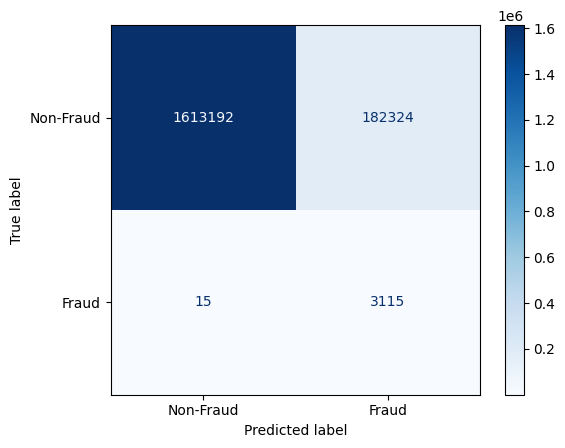

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

### Random Forest

In [17]:
# rf_pipeline = Pipeline([
#     ('preprocessor', preprocessor),
#     ('classifier', RandomForestClassifier(n_estimators=50, max_depth=8, n_jobs=-1, random_state=42, class_weight='balanced', verbose = 1))
# ])
# rf_pipeline.fit(X_train, y_train)

In [ ]:
# y_pred = rf_pipeline.predict(X_test)
# y_proba = rf_pipeline.predict_proba(X_test)[:,1]

# print("Accuracy: ",accuracy_score(y_test, y_pred))
# print("PR-AUC:", average_precision_score(y_test, y_proba))
# print("F1:", f1_score(y_test, y_pred))
# print(classification_report(y_test, y_pred))

In [15]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    scale_pos_weight=scale_pos_weight,
    max_depth=8,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=8, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [19]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: ",accuracy_score(y_test, y_pred_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy:  0.9817963067774315
PR-AUC: 0.18436417934177826
F1: 0.12799616490891658
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.07      0.77      0.13      3130

    accuracy                           0.98   1798646
   macro avg       0.53      0.87      0.56   1798646
weighted avg       1.00      0.98      0.99   1798646



In [20]:
y_train_prob = xgb_pipeline.predict_proba(X_train)[:,1]

print(average_precision_score(y_train,y_train_prob))

0.8193877189746737


In [21]:
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()


In [26]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    scale_pos_weight=200,
    max_depth=5,
    n_estimators=100,
    learning_rate=0.05,
    random_state=42,
    eval_metric='aucpr'
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [27]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: ",accuracy_score(y_test, y_pred_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy:  0.9768292371039103
PR-AUC: 0.1697504738548227
F1: 0.12131562302340292
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.06      0.92      0.12      3130

    accuracy                           0.98   1798646
   macro avg       0.53      0.95      0.55   1798646
weighted avg       1.00      0.98      0.99   1798646



In [28]:
y_train_prob = xgb_pipeline.predict_proba(X_train)[:,1]

print(average_precision_score(y_train,y_train_prob))

0.5921135790175536


In [33]:
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    tree_method='hist',

    n_estimators=300,
    learning_rate=0.05,

    max_depth=4,
    min_child_weight=10,

    subsample=0.8,
    colsample_bytree=0.8,

    gamma=1,

    reg_lambda=2,
    reg_alpha=0,

    scale_pos_weight=200,      
    eval_metric='aucpr',

    random_state=42
)

In [34]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: ",accuracy_score(y_test, y_pred_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy:  0.9768292371039103
PR-AUC: 0.1697504738548227
F1: 0.12131562302340292
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.06      0.92      0.12      3130

    accuracy                           0.98   1798646
   macro avg       0.53      0.95      0.55   1798646
weighted avg       1.00      0.98      0.99   1798646



In [42]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(y_test, y_proba_xgb)
print(f"\nROC AUC Score: {roc_auc:.4f}")


ROC AUC Score: 0.9909


In [1]:
import xgboost as xgb


xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    subsample=0.9,
    n_estimators=1000,
    max_depth=7,
    learning_rate=0.05,
    gamma=0.1,
    colsample_bytree=0.7,
    random_state=42
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=0.1, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=1000, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [2]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

PR-AUC: 0.49554561139839365
F1: 0.31825273010920435
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00   1795516
         1.0       0.85      0.20      0.32      3130

    accuracy                           1.00   1798646
   macro avg       0.93      0.60      0.66   1798646
weighted avg       1.00      1.00      1.00   1798646



In [3]:
y_train_proba_best = xgb_pipeline.predict_proba(X_train)[:, 1]
y_test_proba_best  = xgb_pipeline.predict_proba(X_test)[:, 1]

train_prauc = average_precision_score(y_train, y_train_proba_best)
test_prauc  = average_precision_score(y_test, y_test_proba_best)

print("Train PR-AUC:", train_prauc)
print("Test PR-AUC:", test_prauc)
print("Gap (train - test):", train_prauc - test_prauc)

Train PR-AUC: 0.983338206771824
Test PR-AUC: 0.49554561139839365
Gap (train - test): 0.4877925953734304


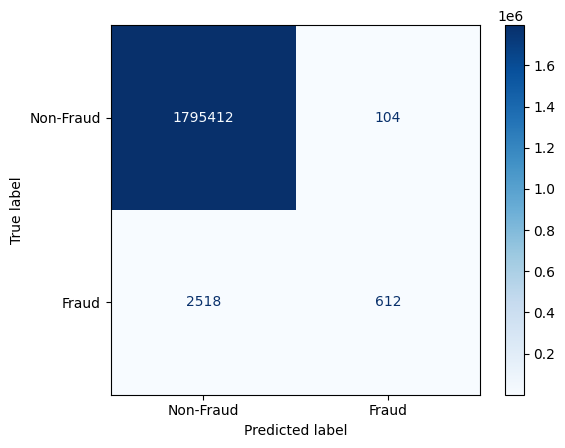

In [45]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

In [47]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    subsample=0.9,
    n_estimators=500,
    max_depth=7,
    learning_rate=0.05,
    gamma=0.1,
    colsample_bytree=0.7,
    random_state=42,
    scale_pos_weight=scale_pos_weight
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=0.1, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=500, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [48]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

PR-AUC: 0.26849055176103104
F1: 0.19053304904051171
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99   1795516
         1.0       0.11      0.71      0.19      3130

    accuracy                           0.99   1798646
   macro avg       0.55      0.85      0.59   1798646
weighted avg       1.00      0.99      0.99   1798646



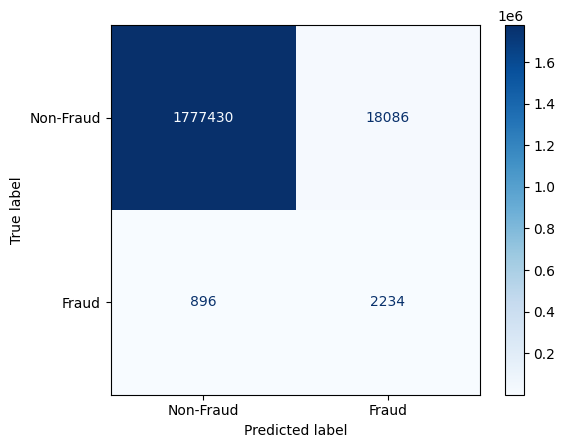

In [49]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

In [1]:
train_corr = train_df['city_fraud_rate'].corr(train_df['target_numeric'])
test_corr = test_df['city_fraud_rate'].corr(test_df['target_numeric'])
print("Train-period correlation:", train_corr)
print("Test-period correlation:", test_corr)

Train-period correlation: 0.21607885355287235
Test-period correlation: 0.13187007995431296


In [1]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.model_selection import train_test_split
import xgboost as xgb

X_search, _, y_search, _ = train_test_split(
    X_train, y_train, train_size=1_000_000, stratify=y_train, random_state=42
)

param_dist = {
    'classifier__max_depth': [3, 4, 5, 6, 7],
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__min_child_weight': [1, 5, 10, 20],
    'classifier__scale_pos_weight': [1, 50, 100, 200, scale_pos_weight],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'classifier__gamma': [0, 0.1, 0.5, 1],
    'classifier__reg_lambda': [1, 2, 5, 10],
}

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(tree_method='hist', random_state=42))
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    xgb_cv_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring='average_precision',
    cv=skf,
    n_jobs=-1,
    verbose=2,
    random_state=42
)

search.fit(X_search, y_search)

print(search.best_params_)
print(search.best_score_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'classifier__subsample': 1.0, 'classifier__scale_pos_weight': 200, 'classifier__reg_lambda': 5, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 5, 'classifier__max_depth': 7, 'classifier__learning_rate': 0.1, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 0.8}
0.7721534795789108


In [2]:
best_params = {
    'tree_method': 'hist',
    'subsample': 1.0,
    'scale_pos_weight': 200,
    'reg_lambda': 5,
    'n_estimators': 500,
    'min_child_weight': 5,
    'max_depth': 7,
    'learning_rate': 0.1,
    'gamma': 0.1,
    'colsample_bytree': 0.8,
    'random_state': 42
}

xgb_best = xgb.XGBClassifier(**best_params)
xgb_best_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', xgb_best)])
xgb_best_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=0.1, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None, min_child_weight=5,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=500,
                               n_jobs=None, num_parallel_tree=None, ...))])

In [3]:
y_train_proba = xgb_best_pipeline.predict_proba(X_train)[:, 1]
y_test_proba = xgb_best_pipeline.predict_proba(X_test)[:, 1]
y_pred_xgb_best_param = xgb_best_pipeline.predict(X_test)

train_prauc = average_precision_score(y_train, y_train_proba)
test_prauc = average_precision_score(y_test, y_test_proba)

print("Train PR-AUC:", train_prauc)
print("Test PR-AUC:", test_prauc)
print("Gap:", train_prauc - test_prauc)
print(classification_report(y_test, y_pred_xgb_best_param))

Train PR-AUC: 0.9664888601386219
Test PR-AUC: 0.24696171558544192
Gap: 0.71952714455318
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00   1795516
         1.0       0.21      0.42      0.28      3130

    accuracy                           1.00   1798646
   macro avg       0.60      0.71      0.64   1798646
weighted avg       1.00      1.00      1.00   1798646



In [11]:
from sklearn.model_selection import TimeSeriesSplit

param_dist_2 = {
    'classifier__max_depth': [3, 4, 5],
    'classifier__n_estimators': [100, 150, 200],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__min_child_weight': [10, 20, 30],
    'classifier__subsample': [0.7, 0.8],
    'classifier__colsample_bytree': [0.6, 0.7, 0.8],
    'classifier__gamma': [0.5, 1, 2],
    'classifier__reg_lambda': [5, 10, 20],
    'classifier__scale_pos_weight': [50, 100, 200],
}


tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_dist_2,
    n_iter=30,
    scoring='average_precision',
    cv=tscv,
    n_jobs=-1,
    verbose=2,
    random_state=42
)

search.fit(X_search, y_search)

print(search.best_params_)
print(search.best_score_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'classifier__subsample': 0.8, 'classifier__scale_pos_weight': 100, 'classifier__reg_lambda': 5, 'classifier__n_estimators': 150, 'classifier__min_child_weight': 20, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__gamma': 2, 'classifier__colsample_bytree': 0.8}
0.6939509620806147
[CV] END classifier__colsample_bytree=0.7, classifier__gamma=1, classifier__learning_rate=0.1, classifier__max_depth=5, classifier__min_child_weight=30, classifier__n_estimators=150, classifier__reg_lambda=20, classifier__scale_pos_weight=200, classifier__subsample=0.7; total time=  11.8s
[CV] END classifier__colsample_bytree=0.6, classifier__gamma=0.5, classifier__learning_rate=0.05, classifier__max_depth=5, classifier__min_child_weight=10, classifier__n_estimators=200, classifier__reg_lambda=20, classifier__scale_pos_weight=100, classifier__subsample=0.7; total time=  26.0s
[CV] END classifier__colsample_bytree=0.7, class

In [12]:
best_params = {
    'tree_method': 'hist',
    'subsample': 0.8,
    'scale_pos_weight': 100,
    'reg_lambda': 5,
    'n_estimators': 150,
    'min_child_weight': 20,
    'max_depth': 5,
    'learning_rate': 0.1,
    'gamma': 2,
    'colsample_bytree': 0.8,
    'random_state': 42
}

xgb_best2 = xgb.XGBClassifier(**best_params)
xgb_best2_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', xgb_best2)])
xgb_best2_pipeline.fit(X_train, y_train)

y_train_proba2 = xgb_best2_pipeline.predict_proba(X_train)[:, 1]
y_test_proba2 = xgb_best2_pipeline.predict_proba(X_test)[:, 1]

train_prauc2 = average_precision_score(y_train, y_train_proba2)
test_prauc2 = average_precision_score(y_test, y_test_proba2)

print("Train PR-AUC:", train_prauc2)
print("Test PR-AUC:", test_prauc2)
print("Gap:", train_prauc2 - test_prauc2)

y_pred2 = xgb_best2_pipeline.predict(X_test)
print(classification_report(y_test, y_pred2))

Train PR-AUC: 0.7734831409576832
Test PR-AUC: 0.3810247196563111
Gap: 0.39245842130137215
              precision    recall  f1-score   support

         0.0       1.00      0.99      1.00   1795516
         1.0       0.13      0.82      0.23      3130

    accuracy                           0.99   1798646
   macro avg       0.57      0.91      0.61   1798646
weighted avg       1.00      0.99      0.99   1798646



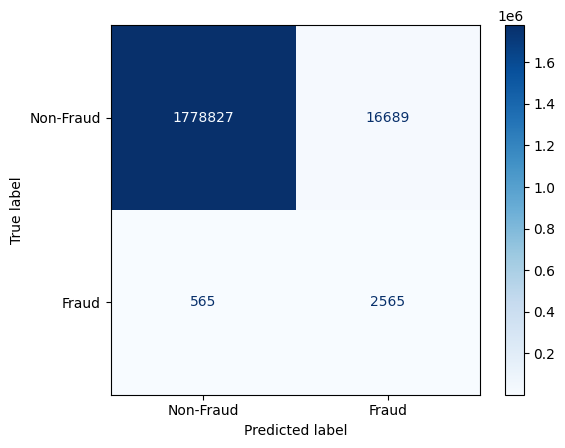

In [2]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred2, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

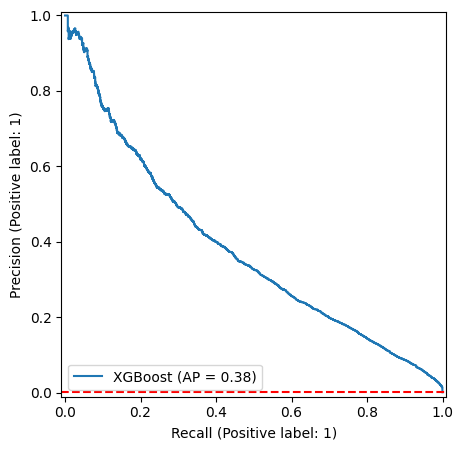

In [16]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, y_test_proba2, ax=ax, name="XGBoost")

#baseline
no_skill = sum(y_test) / len(y_test)
ax.axhline(y=no_skill, color='r', linestyle='--', label=f'No Skill ({no_skill:.2f})')
plt.show()

In [14]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(y_test, y_test_proba2)
f1_scores = 2 * (precision * recall) / (precision + recall + 0.000000001)
best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Precision:", precision[best_idx], "\nRecall:", recall[best_idx], "\nF1:", f1_scores[best_idx])

Best threshold: 0.8539341
Precision: 0.3733441470667748 
Recall: 0.4412140575079872 
F1: 0.40445160295932125


In [17]:
best_threshold = thresholds[best_idx]

y_pred_threshold = (y_test_proba2 >= best_threshold).astype(int)

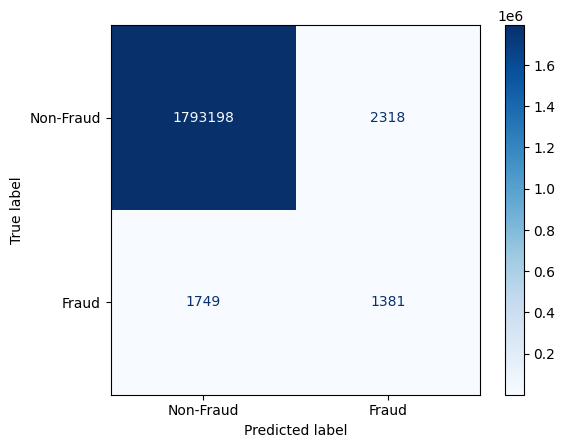

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_threshold, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

- A missed fraud (false negative) costs roughly the transaction amount itself, the bank/customer loses that money outright
- A false alarm (false positive) costs something much smaller per case, a customer service interaction, a temporarily declined legitimate transaction, some customer annoyance, but it happens to a real, often loyal customer, and too many false alarms reduce trust and can cause customers to switch providers

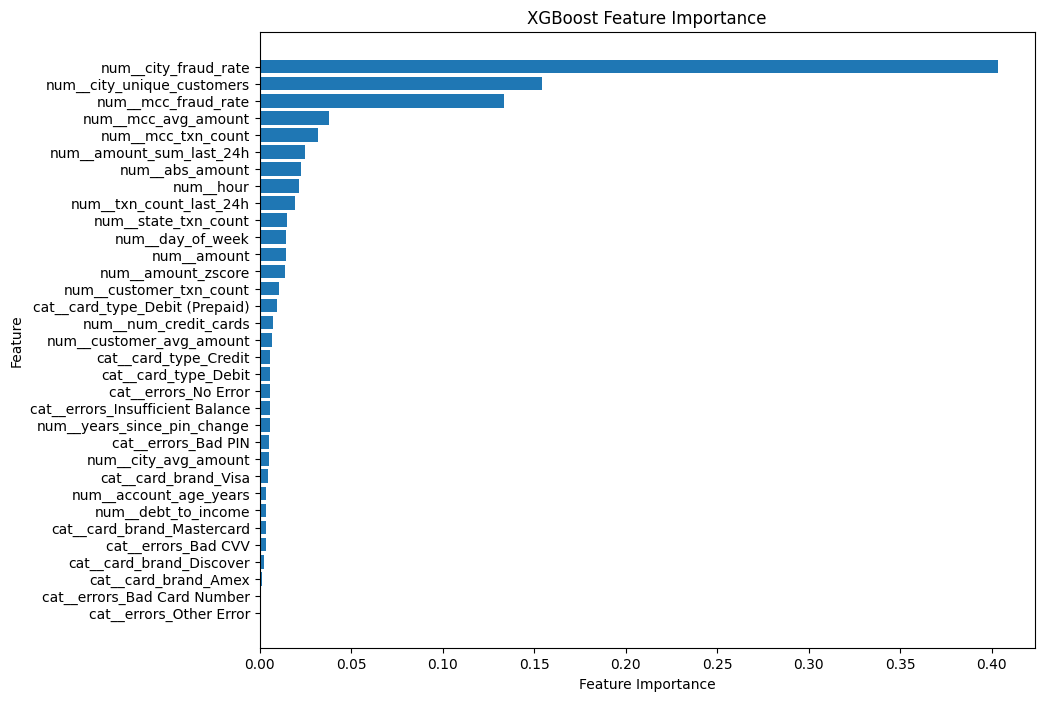

In [4]:
importance_df = pd.DataFrame({
    'Feature': xgb_best_pipeline.named_steps['preprocessor'].get_feature_names_out(),
    'Importance': xgb_best2_pipeline.named_steps['classifier'].feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('XGBoost Feature Importance')
plt.gca().invert_yaxis()
plt.show()

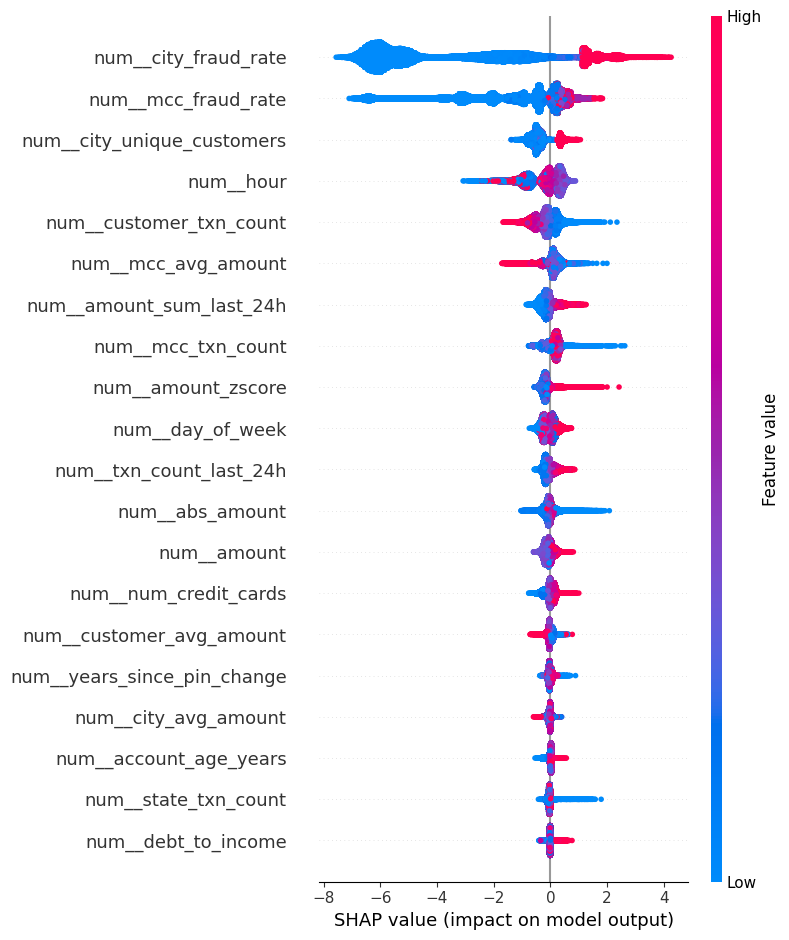

In [15]:
import shap

X_shap_sample = X_train.sample(n=150000, random_state=42)


X_shap_transformed = xgb_best2_pipeline.named_steps['preprocessor'].transform(X_shap_sample)
feature_names = xgb_best2_pipeline.named_steps['preprocessor'].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_best2_pipeline.named_steps['classifier'])
shap_values = explainer.shap_values(X_shap_transformed)

shap.summary_plot(shap_values, X_shap_transformed, feature_names=feature_names)

## Checking Drifts in Data

In [9]:
numerical_cols = X_train.select_dtypes(include='number').columns.tolist()

In [10]:
def calculate_psi(train, test, bins=10):
    # percentile bins
    bin_edges = np.percentile(train, np.linspace(0, 100, bins + 1))
    bin_edges = np.unique(bin_edges)  

    # Percentage of observations in each bin
    train_pct = np.histogram(train, bins=bin_edges)[0] / len(train)
    test_pct = np.histogram(test, bins=bin_edges)[0] / len(test)

    # Avoid division by zero
    train_pct = np.where(train_pct == 0, 0.0001, train_pct)
    test_pct = np.where(test_pct == 0, 0.0001, test_pct)


    
    psi = np.sum((train_pct - test_pct) * np.log(train_pct / test_pct))

    return psi

In [11]:
psi_df = pd.DataFrame({
    'Feature': numerical_cols,
    'PSI': [calculate_psi(train_df[col], test_df[col]) for col in numerical_cols]
})

In [13]:
psi_df[psi_df['PSI']>5]

,Feature,PSI


- No significant drift in numerical cols

In [1]:
categorical_cols = X_train.select_dtypes(include = 'object').columns.to_list()

In [2]:
categorical_cols

['errors', 'card_brand', 'card_type']

In [4]:
def psi_categorical(train_col, test_col):
    train_pct = train_col.value_counts(normalize=True)
    test_pct = test_col.value_counts(normalize=True)
    
    psi_table = pd.DataFrame({'train_pct': train_pct, 'test_pct': test_pct}).fillna(0.0001)
    psi_table['psi'] = (psi_table['test_pct'] - psi_table['train_pct']) * np.log(psi_table['test_pct'] / psi_table['train_pct'])
    
    return psi_table['psi'].sum()

for col in categorical_cols:
    psi_val = psi_categorical(train_df[col], test_df[col])
    print(f"{col} PSI={psi_val:.4f}")

errors PSI=0.0000
card_brand PSI=0.0001
card_type PSI=0.0001


- No data drift in categorical cols too

In [24]:
xgb_v3 = xgb.XGBClassifier(
    tree_method='hist',
    max_depth=4,
    n_estimators=100,
    learning_rate=0.05,
    min_child_weight=30,
    subsample=0.7,
    colsample_bytree=0.7,
    gamma=3,
    reg_lambda=15,
    scale_pos_weight=100,
    random_state=42
)

In [25]:
xgb_pipeline_v3 = Pipeline([('preprocessor', preprocessor), ('classifier', xgb_v3)])
xgb_pipeline_v3.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=3, grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=30, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [26]:
y_train_proba_v3 = xgb_pipeline_v3.predict_proba(X_train)[:, 1]
y_test_proba_v3 = xgb_pipeline_v3.predict_proba(X_test)[:, 1]

train_pr_auc_v3 = average_precision_score(y_train, y_train_proba_v3)
test_pr_auc_v3 = average_precision_score(y_test, y_test_proba_v3)

print("Train PR-AUC:", train_pr_auc_v3)
print("Test PR-AUC:", test_pr_auc_v3)
print("Gap:", train_pr_auc_v3 - test_pr_auc_v3)

y_pred_v3 = xgb_pipeline_v3.predict(X_test)
print(classification_report(y_test, y_pred_v3))

Train PR-AUC: 0.5067089319415425
Test PR-AUC: 0.2720641671660506
Gap: 0.23464476477549195
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.08      0.92      0.15      3130

    accuracy                           0.98   1798646
   macro avg       0.54      0.95      0.57   1798646
weighted avg       1.00      0.98      0.99   1798646



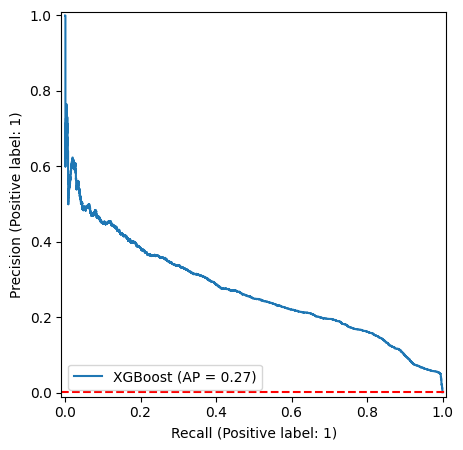

In [27]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, y_test_proba_v3, ax=ax, name="XGBoost")

no_skill = sum(y_test) / len(y_test)
ax.axhline(y=no_skill, color='r', linestyle='--', label=f'No Skill ({no_skill:.2f})')
plt.show()

In [28]:
precision, recall, thresholds = precision_recall_curve(y_test, y_test_proba_v3)
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best Threshold:", best_threshold)
print("Best F1-score:", f1_scores[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])

Best Threshold: 0.8275224
Best F1-score: 0.33978132880084316
Precision: 0.2722896206431735
Recall: 0.4517571884984026


In [31]:
def objective(trial):
    params = {
        'tree_method': 'hist',
        'n_jobs': -1,
        'max_depth': trial.suggest_int('max_depth', 4, 6),
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 10, 30),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.5, 3),
        'reg_lambda': trial.suggest_float('reg_lambda', 1, 20, log=True),
        'scale_pos_weight': trial.suggest_int('scale_pos_weight', 50, 250),
        'random_state': 42
    }

    model = xgb.XGBClassifier(**params)
    pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', model)])

    tscv = TimeSeriesSplit(n_splits=3)
    scores = []
    for train_idx, val_idx in tscv.split(X_search):
        X_tr, X_val = X_search.iloc[train_idx], X_search.iloc[val_idx]
        y_tr, y_val = y_search.iloc[train_idx], y_search.iloc[val_idx]

        pipeline.fit(X_tr, y_tr)
        proba = pipeline.predict_proba(X_val)[:, 1]
        scores.append(average_precision_score(y_val, proba))

    return np.mean(scores)

X_search = X_train.iloc[-2_000_000:]
y_search = y_train.iloc[-2_000_000:]

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=25, show_progress_bar=True)

print(study.best_params)
print(study.best_value)

[I 2026-06-29 11:22:41,235] A new study created in memory with name: no-name-4953deab-c68a-44fc-9065-adb4939a2181


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-06-29 11:23:45,196] Trial 0 finished with value: 0.49350637401438685 and parameters: {'max_depth': 5, 'n_estimators': 291, 'learning_rate': 0.09744578609310868, 'min_child_weight': 22, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.662397808134481, 'gamma': 0.6452090304204987, 'reg_lambda': 13.39433470675048, 'scale_pos_weight': 170}. Best is trial 0 with value: 0.49350637401438685.
[I 2026-06-29 11:24:16,445] Trial 1 finished with value: 0.4723158648996342 and parameters: {'max_depth': 6, 'n_estimators': 104, 'learning_rate': 0.14290885785088342, 'min_child_weight': 27, 'subsample': 0.7637017332034828, 'colsample_bytree': 0.6727299868828402, 'gamma': 0.9585112746335845, 'reg_lambda': 2.4878734419814426, 'scale_pos_weight': 155}. Best is trial 0 with value: 0.49350637401438685.
[I 2026-06-29 11:24:55,567] Trial 2 finished with value: 0.46366870243967057 and parameters: {'max_depth': 5, 'n_estimators': 158, 'learning_rate': 0.0803134117264377, 'min_child_weight': 12, 'su

In [32]:
best_params = {
    'tree_method': 'hist',
    'n_jobs': -1,
    'max_depth': study.best_params['max_depth'],
    'n_estimators': study.best_params['n_estimators'],
    'learning_rate': study.best_params['learning_rate'],
    'min_child_weight': study.best_params['min_child_weight'],
    'subsample': study.best_params['subsample'],
    'colsample_bytree': study.best_params['colsample_bytree'],
    'gamma': study.best_params['gamma'],
    'reg_lambda': study.best_params['reg_lambda'],
    'scale_pos_weight': study.best_params['scale_pos_weight'],
    'random_state': 42
}

print(best_params)

xgb_optuna = xgb.XGBClassifier(**best_params)
xgb_optuna_pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', xgb_optuna)])

xgb_optuna_pipeline.fit(X_train, y_train)

{'tree_method': 'hist', 'n_jobs': -1, 'max_depth': 6, 'n_estimators': 271, 'learning_rate': 0.149091510917455, 'min_child_weight': 20, 'subsample': 0.8843970766669649, 'colsample_bytree': 0.7636004284281295, 'gamma': 0.846924848576497, 'reg_lambda': 1.0354263660840601, 'scale_pos_weight': 139, 'random_state': 42}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               gamma=0.846924848576497, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.149091510917455, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=6,
                               max_leaves=None, min_child_weight=20,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=271, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [33]:
y_train_proba_opt = xgb_optuna_pipeline.predict_proba(X_train)[:, 1]
y_test_proba_opt = xgb_optuna_pipeline.predict_proba(X_test)[:, 1]

train_prauc_opt = average_precision_score(y_train, y_train_proba_opt)
test_prauc_opt = average_precision_score(y_test, y_test_proba_opt)

print("Train PR-AUC:", train_prauc_opt)
print("Test PR-AUC:", test_prauc_opt)
print("Gap:", train_prauc_opt - test_prauc_opt)

y_pred_opt = xgb_optuna_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_opt))

Train PR-AUC: 0.9086980496814397
Test PR-AUC: 0.3176580159316769
Gap: 0.5910400337497628
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00   1795516
         1.0       0.19      0.59      0.29      3130

    accuracy                           0.99   1798646
   macro avg       0.59      0.79      0.64   1798646
weighted avg       1.00      0.99      1.00   1798646



In [34]:
precision, recall, thresholds = precision_recall_curve(y_test, y_test_proba_opt)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Precision:", precision[best_idx], "Recall:", recall[best_idx], "F1:", f1_scores[best_idx])

Best threshold: 0.77080923
Precision: 0.33136729222520106 Recall: 0.394888178913738 F1: 0.3603498537312302


In [1]:
train_df.head()

,amount,use_chip,errors,abs_amount,target_numeric,gender,num_credit_cards,card_brand,card_type,has_chip,...,amount_zscore,mcc_fraud_rate,mcc_avg_amount,mcc_txn_count,city_fraud_rate,city_avg_amount,city_unique_customers,state_txn_count,client_fraud_rate,is_online
0,-77.00,Swipe Transaction,No Error,77.00,0.0,1,4,Mastercard,Debit (Prepaid),1,...,0.101336,0.000002,41.348915,807904,0.000000,68.709122,13,12388,0.003477,0
1,80.00,Swipe Transaction,No Error,80.00,0.0,0,3,Mastercard,Debit,1,...,0.459925,0.002286,90.184654,317560,0.000000,68.977081,40,773095,0.000629,0
2,14.57,Swipe Transaction,No Error,14.57,0.0,0,5,Mastercard,Credit,1,...,-0.380896,0.006168,56.963947,255855,0.000000,59.643684,16,86235,0.005267,0
3,46.41,Swipe Transaction,No Error,46.41,0.0,0,2,Visa,Debit,1,...,-0.413219,0.000599,25.170216,133609,0.001356,66.795120,5,104472,0.001960,0
4,4.81,Swipe Transaction,No Error,4.81,0.0,1,5,Mastercard,Debit (Prepaid),1,...,-0.599840,0.000353,19.289579,124678,0.000000,47.624516,169,464253,0.000749,0
